# 4. SevenNet-Polar: Born effective charges

In an ionic crystal, moving an atom changes the polarization. The **Born effective charge** tensor
Z\*<sub>i,ab</sub> = ∂P<sub>a</sub>/∂r<sub>i,b</sub> measures that change; it controls infrared
activity, the splitting of longitudinal and transverse optical phonons, and the force on an atom in an
electric field. DFT gets it from expensive linear-response calculations. SevenNet-Polar predicts it
alongside energy, forces and stress.

We use two public SevenNet-Polar models (Lu *et al.*, data and models at
[doi:10.5281/zenodo.23734482](https://doi.org/10.5281/zenodo.23734482), CC-BY-4.0), downloaded once and
cached:

* **SevenNet-PM-S**, multitask: energy, forces, stress and Z\* for ZrO₂ and Li₃PO₄;
* **SevenNet-PS-S**, specialized: Z\* only, for ZrO₂, Li₃PO₄ and perovskite oxides.

On a machine with more memory, **SevenNet-PM-M** (`'SevenNet-PM-M.pth'`) is the larger multitask model.

The structures are 24 frames of the same record, with their DFT values of Z\*. They come from the
data the models were trained and validated on, so the comparison below is a consistency check, not a
test on unseen structures.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import _tutorial as T

warnings.filterwarnings('ignore', message='.*torch.jit.script.*')   # deprecation inside a dependency, harmless here
plt.rcParams['figure.dpi'] = 200   # sharp inline figures
T.machine_report()

machine : Apple M5 Pro, 52 GB memory, Darwin 27.2.0
python  : 3.13.9, torch 2.15.0, sevenn 0.12.2.dev0
Apple GPU (MPS): yes; fused kernels: available


In [2]:
from ase.io import read

pm_s = T.zenodo_file('SevenNet-PM-S.pth')
ps_s = T.zenodo_file('SevenNet-PS-S.pth')
frames = read(T.HERE / 'data' / 'zro2_li3po4_sample.extxyz', index=':')
print(len(frames), 'frames:', sorted({a.get_chemical_formula(mode='reduce') for a in frames}))

24 frames: ['Li11P4O16', 'Li12P4O16', 'Li22P8O31', 'Zr16O31', 'Zr16O32', 'Zr32O63', 'Zr32O64']


## Predict Z\* and compare with DFT

Converting model backend...


Converting model backend...


24 frames, two models, Apple GPU, fused: 1.5 s


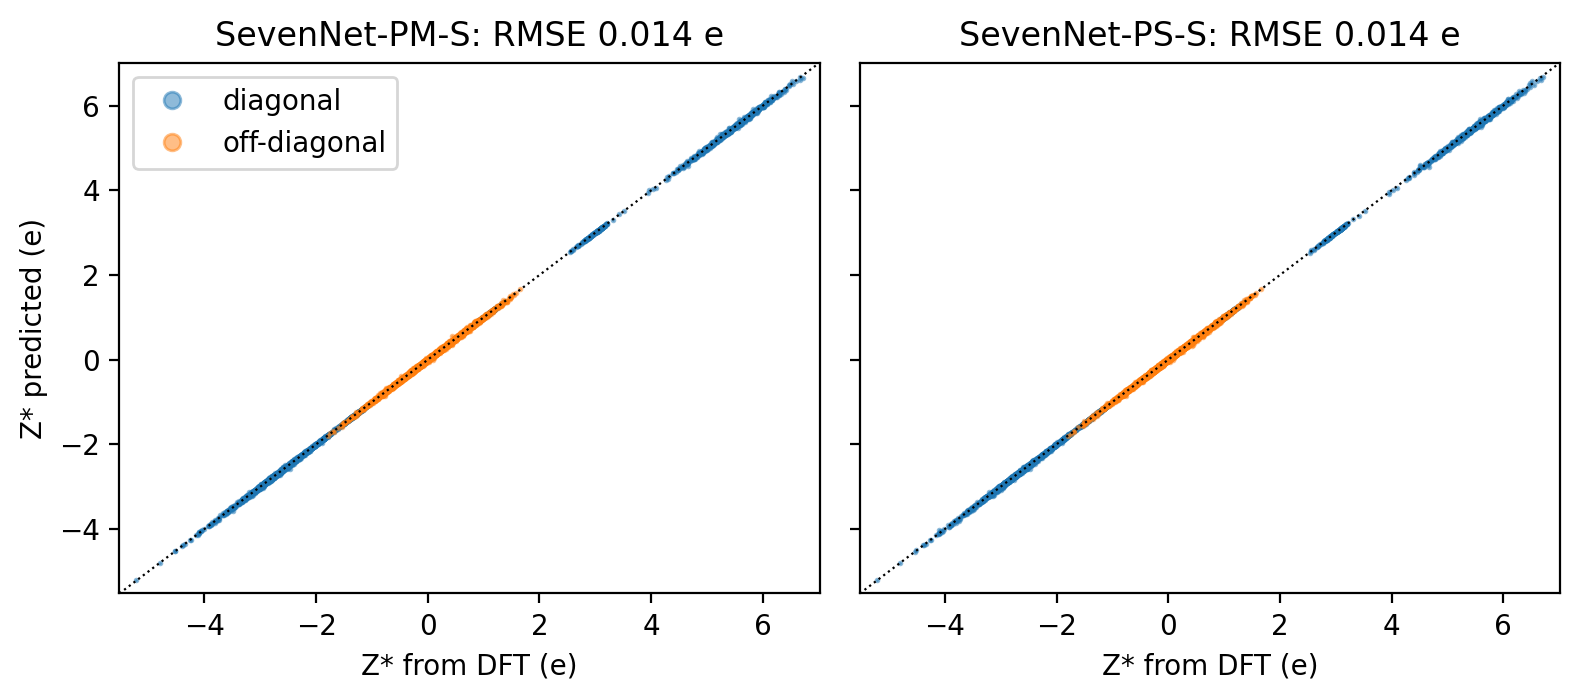

In [3]:
label, device, opt = T.best_backend()
models = {'PM-S': T.calculator(pm_s, device, opt), 'PS-S': T.calculator(ps_s, device, opt)}
pred = {k: [] for k in models}
dft = []
t = time.perf_counter()
for a in frames:
    dft.append(a.calc.results['born_effective_charges'].reshape(-1, 3, 3))
    for k, calc in models.items():
        b = a.copy()
        b.calc = calc
        b.get_potential_energy()
        pred[k].append(np.asarray(calc.results['born_effective_charges']).reshape(-1, 3, 3))
print(f'{len(frames)} frames, two models, {label}: {time.perf_counter() - t:.1f} s')

fig, axs = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
D = np.concatenate(dft)
for ax, k in zip(axs, models):
    P = np.concatenate(pred[k])
    diag = np.eye(3, dtype=bool)
    ax.plot(D[:, diag].ravel(), P[:, diag].ravel(), '.', ms=2, alpha=0.5, label='diagonal')
    ax.plot(D[:, ~diag].ravel(), P[:, ~diag].ravel(), '.', ms=2, alpha=0.5, label='off-diagonal')
    lim = [D.min() - 0.3, D.max() + 0.3]
    ax.plot(lim, lim, 'k:', lw=0.8)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    rmse = np.sqrt(np.mean((P - D) ** 2))
    ax.set_title(f'SevenNet-{k}: RMSE {rmse:.3f} e')
    ax.set_xlabel('Z* from DFT (e)')
axs[0].set_ylabel('Z* predicted (e)')
axs[0].legend(markerscale=6)
plt.tight_layout()
plt.show()

## The acoustic sum rule

Moving the whole crystal rigidly does not change its polarization, so in a neutral cell the Born
charges of all atoms sum to zero for each Cartesian component. In a cell that carries a net charge Q,
the sum is Q on the diagonal instead. The sample has such cells: Li₃PO₄ with one Li removed, keeping the
electrons, so Q = −1 e. The models are not constrained to obey either rule exactly; how close they come
is a useful check.

In [4]:
from collections import defaultdict

groups = defaultdict(list)
for i, a in enumerate(frames):
    groups[a.get_chemical_formula(mode='hill')].append(i)
print(f'{"cell":12s} {"DFT":>7s} {"PM-S":>7s} {"PS-S":>7s}   (diagonal of the sum over atoms, mean over frames, e)')
for f, idx in sorted(groups.items()):
    row = [np.mean([np.trace(z[i].sum(axis=0)) / 3 for i in idx]) for z in (dft, pred['PM-S'], pred['PS-S'])]
    print(f'{f:12s} ' + ' '.join(f'{v:7.3f}' for v in row))

cell             DFT    PM-S    PS-S   (diagonal of the sum over atoms, mean over frames, e)
Li11O16P4     -1.013  -1.014  -1.015
Li12O16P4     -0.012  -0.026  -0.018
Li22O31P8     -0.028   0.037  -0.017
O31Zr16       -0.000  -0.013   0.015
O32Zr16       -0.000  -0.004   0.010
O63Zr32        0.000  -0.075  -0.093
O64Zr32        0.000   0.076   0.059


The neutral cells sum to zero, and the charged cells to about −1 e, in DFT and in both models: they
have learnt the rule from the data. The finite-field calculator below can enforce the neutral rule
exactly (`enforce_asr=True`).

## Forces in an electric field

To first order, a uniform field **E** adds a force on each atom given by its Born charge:
F<sub>i,b</sub>(E) − F<sub>i,b</sub>(0) = Σ<sub>a</sub> Z\*<sub>i,ab</sub> E<sub>a</sub>.
`FieldCalculator` wraps a SevenNet-Polar calculator to add it, which is what MD in a field uses. We
check the relation on one ZrO₂ cell, with the sum rule enforced (`enforce_asr=True`).

In [5]:
from sevenn.calculator import FieldCalculator

a = next(f for f in frames if set(f.get_chemical_symbols()) == {'Zr', 'O'}).copy()
base = T.calculator(pm_s, device, opt)
field = FieldCalculator(base, enforce_asr=True)
E = np.array([0.0, 0.0, 0.05])                          # V/Å
a.calc = field
field.set_efield([0.0, 0.0, 0.0])
F0 = a.get_forces().copy()
field.set_efield(E)
F1 = a.get_forces().copy()
Z = np.asarray(field.results['born_effective_charges']).reshape(-1, 3, 3)
expected = np.einsum('iab,a->ib', Z, E)
print('max |(F(E) - F(0)) - Z*ᵀE| =', f'{np.abs((F1 - F0) - expected).max():.1e} eV/Å',
      f'(field forces up to {np.abs(expected).max():.3f} eV/Å)')

Converting model backend...


max |(F(E) - F(0)) - Z*ᵀE| = 9.5e-07 eV/Å (field forces up to 0.310 eV/Å)


The field force is exactly the Born-charge term. With it, molecular dynamics in a field runs as in
the previous notebook, with `FieldCalculator` in place of the plain calculator.

**Next experiments:** compare the time of the Z\* predictions on the CPU and the GPU
(`T.available_backends()`), or predict Z\* along an MD trajectory of ZrO₂ from notebook 2 using PM-S.